# Phaedrus Screening
Short Phaedrus example notebook using the unified scalar BVP solver.

- Sweep over $\delta_c$
- Double-panel screening plot
- Phaedrus screening radii from the sweep

Note: modules are loaded from `../main`.

In [1]:
import sys, importlib
from pathlib import Path

cwd = Path.cwd().resolve()
repo_root = next(
    (
        p for p in (cwd, cwd.parent, cwd.parent.parent)
        if (p / "main" / "physics_utils.py").exists()
    ),
    None,
)
if repo_root is None:
    raise RuntimeError(f"Could not locate project root from cwd={cwd}")

main_dir = str(repo_root / "main")
if main_dir not in sys.path:
    sys.path.insert(0, main_dir)

import physics_utils as _physics_mod
importlib.reload(_physics_mod)
import plotting as _plotting_mod
importlib.reload(_plotting_mod)
import escut
importlib.reload(escut)

from escut import (
    solve_scalar_bvp,
    plot_double_panel,
    compute_n_slope,
)

import numpy as np
import matplotlib.pyplot as plt

## Sweep over δc
We vary the central overdensity $\delta_c$, solve for each, and produce the
double-panel figure (flux on top, slope $n(x)$ on bottom) coloured by $\log_{10}(\delta_c)$.

In [2]:
A = 1.0
B = 0
C = 0
D = 1.0
E = 1.0
F = 0.0
S = 1.0
delta_inf = 0
eps_edge = 0.015

xmin, xmax = 1e-2, 1e6
npoints = 4500
tol = 1e-6
max_nodes = 3_000_000

delta_cs = np.logspace(1, 6, 6)
sols = []
linrefs = []
for dc in delta_cs:
    sol = solve_scalar_bvp(A=A, B=0.0, C=0.0, D=D, E=E, F=F,
                           S=S, delta_c=dc, delta_inf=delta_inf, eps_edge=eps_edge,
                           xmin=xmin, xmax=xmax, npoints=npoints, tol=tol, homotopy=True, max_nodes=max_nodes)
    sols.append(sol)
    sol_lin = solve_scalar_bvp(A=A, B=0.0, C=0.0, D=0, E=0, F=0.0,
                               S=S, delta_c=dc, delta_inf=delta_inf, eps_edge=eps_edge,
                               xmin=xmin, xmax=xmax, npoints=npoints, tol=tol, homotopy=True, max_nodes=max_nodes)
    linrefs.append(sol_lin)

x = np.logspace(np.log10(xmin), np.log10(xmax), 1200)


/var/folders/v5/cvwhs2xn4xx7dclcy1bm90840000gq/T/ipykernel_53448/3675101800.py:55: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_v = cm.get_cmap("viridis")


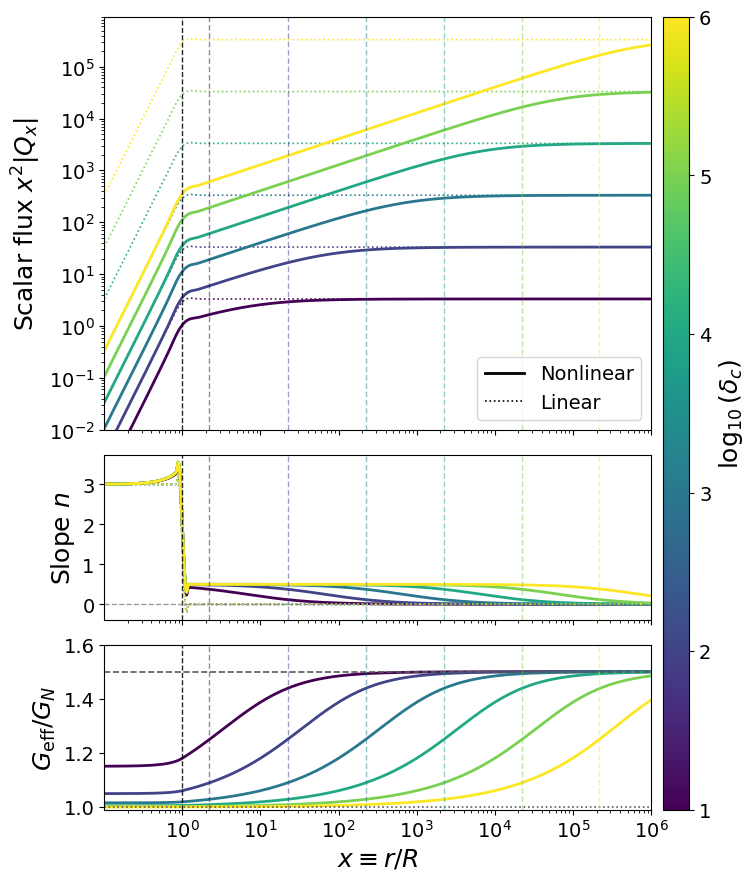

{0: {'xV_full': None,
  'xV_mu': 2.3709226160012284,
  'xV_exact': None,
  'delta_c': np.float64(10.0)},
 1: {'xV_full': None,
  'xV_mu': 5.107997931294189,
  'xV_exact': None,
  'delta_c': np.float64(100.0)},
 2: {'xV_full': None,
  'xV_mu': 11.0048479397913,
  'xV_exact': None,
  'delta_c': np.float64(1000.0)},
 3: {'xV_full': None,
  'xV_mu': 23.709226160012282,
  'xV_exact': None,
  'delta_c': np.float64(10000.0)},
 4: {'xV_full': None,
  'xV_mu': 51.079979312941894,
  'xV_exact': None,
  'delta_c': np.float64(100000.0)},
 5: {'xV_full': None,
  'xV_mu': 110.048479397913,
  'xV_exact': None,
  'delta_c': np.float64(1000000.0)}}

In [3]:
from matplotlib.lines import Line2D
from matplotlib.colors import Normalize
from physics_utils import _cross_at_one
import matplotlib.cm as cm

# Three-panel figure for the Phaedrus sweep: scalar flux x^2|Q'| (top), local
# slope n(x) (middle), and the Jordan-frame effective Newton constant
# G_eff/G_N = Phi'/Phi'_GR (bottom).  Substituting the screened flux back into
# the metric equations gives G_eff/G_N = 1 + (alpha_B+2 alpha_M)^2/(2 Gamma) * Q'/Q'_lin,
# which returns to 1 (GR) wherever the flux is screened and saturates to the
# unscreened enhancement far out.  Gamma = A = 1 here; the representative
# couplings alpha_B = 1/2, alpha_M = 1/4 give (alpha_B+2 alpha_M)^2/(2 Gamma) = 1/2,
# i.e. an unscreened value G_eff/G_N -> 3/2.  Flux panel keeps its 2.5:1 height
# to match the other mechanisms' figures; G_eff shares n's height.
alpha_B, alpha_M = 0.5, 0.25

x_plot = x[x >= 1e-1]
fig, (ax_top, ax_bot, ax_geff), xV_map = plot_double_panel(
    x_plot, sols,
    linrefs=linrefs,
    cmap_name="viridis",
    lw_num=2.0, lw_lin=1.2, lin_ls=":",
    smooth_win_deriv=61, smooth_poly_deriv=3,
    smooth_win_vain=21, smooth_poly_vain=3,
    S=S, delta_inf=delta_inf, eps_edge=eps_edge,
    figsize=(8, 10.3),
    vradius="none",
    vline_alpha=0.5, vline_lw=1.0, vline_ls="striped",
    show_horizontal_guides=False,
    geff_panel=True, alpha_B=alpha_B, alpha_M=alpha_M,
    label_fontsize=18,
    tick_fontsize=14,
    cbar_fontsize=18,
)

for ax_ in [ax_top, ax_bot, ax_geff]:
    ax_.grid(True, which='major', alpha=0.0)
    ax_.grid(True, which='minor', alpha=0.0)

ax_bot.axhline(0.0, color='gray', ls='--', lw=1.0, alpha=0.8)

legend_elements = [
    Line2D([0], [0], color='black', lw=2.0, label='Nonlinear'),
    Line2D([0], [0], color='black', lw=1.2, linestyle=':', label='Linear'),
]
ax_top.legend(handles=legend_elements, loc='lower right', fontsize=14)

ax_top.set_ylim(bottom=1e-2)

ax_bot.set_yticks([0, 1, 2, 3])
ax_bot.set_yticklabels(['0', '1', '2', '3'], fontsize=14)

x_fine = np.logspace(np.log10(float(x_plot[0])), np.log10(float(x_plot[-1])), 3000)
norm_v = Normalize(vmin=np.log10(delta_cs.min()), vmax=np.log10(delta_cs.max()))
cmap_v = cm.get_cmap("viridis")

for sol_i, dc in zip(sols, delta_cs):
    meta = getattr(sol_i, "meta", {}) or {}
    pars = meta.get("pars_full", None)
    if pars is None:
        continue
    A_i, _, _, D_i, _, _, _, _ = pars
    if A_i == 0 or D_i == 0:
        continue
    Q_fine = sol_i.sol(x_fine)[0]
    ratio = D_i * np.abs(Q_fine) / abs(A_i)
    x_pscr = _cross_at_one(x_fine, ratio)
    if x_pscr is None:
        continue
    col = cmap_v(norm_v(np.log10(dc)))
    for ax_ in [ax_top, ax_bot, ax_geff]:
        ax_.axvline(x_pscr, color=col, ls=(0, (4, 2)), lw=1.0, alpha=0.5, label="_noref")

fig.savefig('phaedrus_triple_panel.pdf', dpi=300, bbox_inches='tight')
plt.show()
xV_map
